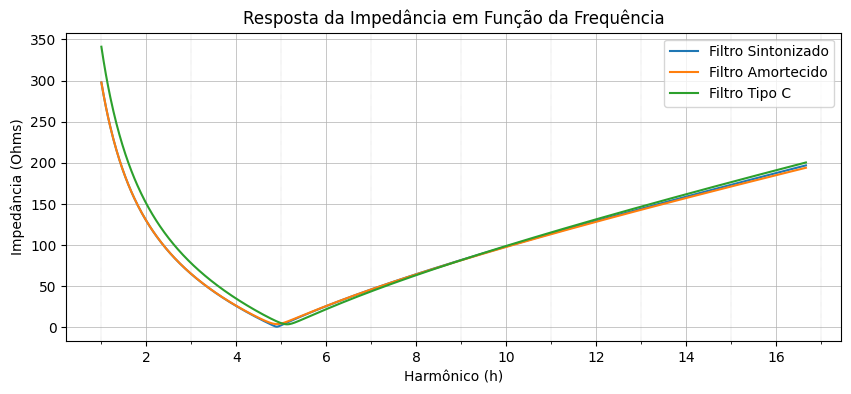

In [31]:
import matplotlib.pyplot as plt
import numpy as np

# Parâmetros dos filtros
R_sintonizado = 0.792  # Ohms
L_sintonizado = 34.30e-3  # H
C_sintonizado = 8.54e-6  # F

R_amortecido = R_sintonizado
R_paralelo_amortecido = 1260  # Ohms
L_amortecido = L_sintonizado
C_amortecido = C_sintonizado


La = 35.79e-3  # H
Ca_serie = 60.25e-6  # F
C_serie = C_sintonizado

# Frequências para a análise
frequencias = np.arange(60, 1001, 1)  # Hz
omega = 2 * np.pi * frequencias  # rad/s

# Funções para calcular a impedância de cada filtro
def calc_impedancia_sintonizado(R, L, C, omega):
    return R + 1j * (omega * L - 1 / (omega * C))

def calc_impedancia_amortecido(R, L, C, R_paralelo, omega):
    ZL = 1j * omega * L
    ZC = 1 / (1j * omega * C)
    ZRL = R + ZL
    return 1 / (1 / ZRL + 1 / R_paralelo) + ZC

def calc_impedancia_tipoC(R, L, Ca, C, R_paralelo, omega):
    ZL = 1j * omega * L
    ZCa = 1 / (1j * omega * Ca)
    ZC = 1 / (1j * omega * C)
    ZRLCa = R + ZL + ZCa
    return 1 / (1 / ZRLCa + 1 / R_paralelo) + ZC

# Calculando as impedâncias
Z_sintonizado = calc_impedancia_sintonizado(R_sintonizado, L_sintonizado, C_sintonizado, omega)
Z_amortecido = calc_impedancia_amortecido(R_amortecido, L_amortecido, C_amortecido, R_paralelo_amortecido, omega)
Z_serie_paralelo = calc_impedancia_tipoC(R_sintonizado, La, Ca_serie, C_serie, R_paralelo_amortecido, omega)

# Plotando o gráfico
plt.figure(figsize=(10, 4))
plt.plot(frequencias/60, np.abs(Z_sintonizado), label='Filtro Sintonizado')
plt.plot(frequencias/60, np.abs(Z_amortecido), label='Filtro Amortecido')
plt.plot(frequencias/60, np.abs(Z_serie_paralelo), label='Filtro Tipo C')
plt.title('Resposta da Impedância em Função da Frequência')
plt.xlabel('Harmônico (h)')
plt.ylabel('Impedância (Ohms)')
plt.legend()
plt.grid(which='major', linestyle='-', linewidth='0.5')
major_ticks = plt.gca().get_xticks()
minor_ticks = (major_ticks[:-1] + major_ticks[1:]) / 2
plt.gca().set_xticks(minor_ticks, minor=True)
plt.grid(which='minor', axis='x', linestyle=':', linewidth='0.25', color='gray')
plt.show()


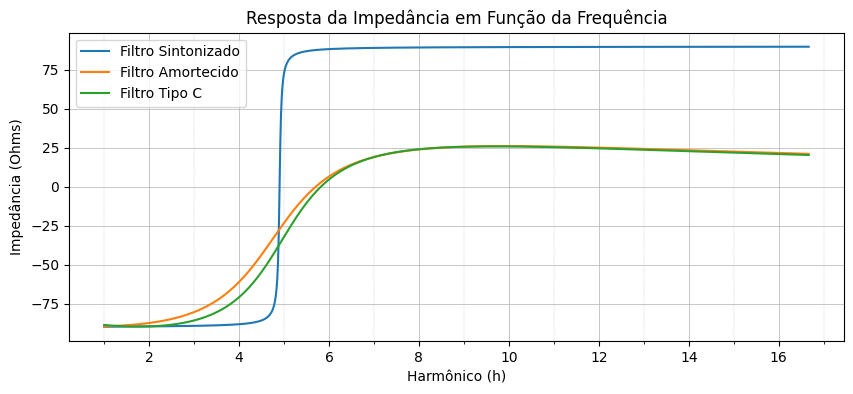

In [28]:
# Plotando o gráfico
plt.figure(figsize=(10, 4))
plt.plot(frequencias/60, np.angle(Z_sintonizado, deg=True), label='Filtro Sintonizado')
plt.plot(frequencias/60, np.angle(Z_amortecido, deg=True), label='Filtro Amortecido')
plt.plot(frequencias/60, np.angle(Z_serie_paralelo, deg=True), label='Filtro Tipo C')
plt.title('Resposta da Impedância em Função da Frequência')
plt.xlabel('Harmônico (h)')
plt.ylabel('Impedância (Ohms)')
plt.legend()
plt.grid(which='major', linestyle='-', linewidth='0.5')
major_ticks = plt.gca().get_xticks()
minor_ticks = (major_ticks[:-1] + major_ticks[1:]) / 2
plt.gca().set_xticks(minor_ticks, minor=True)
plt.grid(which='minor', axis='x', linestyle=':', linewidth='0.25', color='gray')
plt.show()

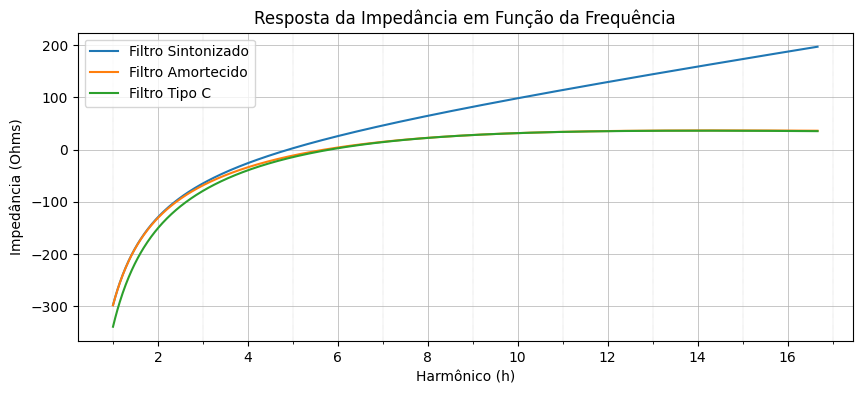

In [29]:
# Plotando o gráfico
plt.figure(figsize=(10, 4))
plt.plot(frequencias/60, np.imag(Z_sintonizado), label='Filtro Sintonizado')
plt.plot(frequencias/60, np.imag(Z_amortecido), label='Filtro Amortecido')
plt.plot(frequencias/60, np.imag(Z_serie_paralelo), label='Filtro Tipo C')
plt.title('Resposta da Impedância em Função da Frequência')
plt.xlabel('Harmônico (h)')
plt.ylabel('Impedância (Ohms)')
plt.legend()
plt.grid(which='major', linestyle='-', linewidth='0.5')
major_ticks = plt.gca().get_xticks()
minor_ticks = (major_ticks[:-1] + major_ticks[1:]) / 2
plt.gca().set_xticks(minor_ticks, minor=True)
plt.grid(which='minor', axis='x', linestyle=':', linewidth='0.25', color='gray')
plt.show()